# Bartlett correction — does a finite-sample fix cure the overconfidence? (Phase 3)

**Question.** The Asimov property breaks in the non-asymptotic regime: toy 68% intervals are too
narrow, so they under-cover the truth (overconfidence). The **Bartlett correction** rescales the
likelihood-ratio statistic by its finite-sample mean, $t' = t/\mathbb{E}[t]$, so that $\mathbb{E}[t']=1$
and the $\chi^2$ thresholds become valid again (foundations note §13). Does it work here?

**Design — a coverage test** (the honest operationalisation; rescaling both curves by a common
per-$\mu$ factor is nearly invariant for the *curve values*, so we test *intervals* instead). Toys are
thrown at the SM truth $\mu=1$. For each toy:
- **naive** 68% interval = where $t_{\rm toy}(\mu)=1$ (the asymptotic $\chi^2_1$ threshold);
- **Bartlett** interval = where $t_{\rm toy}(\mu)=\mathbb{E}[t_\mu]$, with $\mathbb{E}[t_\mu]$ the mean over the toy
  ensemble at each $\mu$ (equivalently $t'=t/\mathbb{E}[t]$ crossing 1).

Coverage = fraction of toy intervals containing $\mu=1$; nominal is 68.3%. Overconfident → naive
coverage < 68%; a working correction → Bartlett coverage → 68%.

**Inputs.** Reuses the saved scan tensors from the histogram and dimensionality runs
(`output/hist/`, `output/dim/`) — no re-running. CPU, seconds.
**Caveat noted up front:** $\mathbb{E}[t_\mu]$ is estimated in-sample from the same 200 toys (mildly
optimistic); intervals that do not close inside the $\mu$ scan window extend to its edge.

## 1. Setup

In [1]:
import os, numpy as np, torch
import matplotlib.pyplot as plt
ROOT = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
MU_TRUTH = 1.0; NOMINAL = 0.6827

def load(path):
    mu = torch.load(f'{path}/poi_scan.pt', map_location='cpu').numpy()
    a  = torch.load(f'{path}/nll_scan_asimov.pt', map_location='cpu').numpy()
    t  = torch.load(f'{path}/nll_scan_toys.pt', map_location='cpu').numpy()   # (n_mu, n_toys)
    return mu, a, t

# configs where 1-sigma intervals generally close: 100 & 1000 fb^-1, plus 1D histogram control
CONFIGS = []
for L in (100, 1000):
    for d in (1,2,3,4):
        CONFIGS.append((f'occ_{d}d @ {L}fb', f'{ROOT}/output/dim/occ_{d}d_lumi_{L}', d, L))
    for d in (1,2,3,4):
        CONFIGS.append((f'ctl_{d}d @ {L}fb', f'{ROOT}/output/dim/ctl_{d}d_lumi_{L}', d, L))
CONFIGS.append(('hist_1d @ 1000fb', f'{ROOT}/output/hist/lumi_1000', 1, 1000))
N_EXP_1FB = 5.656

## 2. Interval + coverage machinery

`interval(t, mu, level)` returns the region around the curve minimum where $t\le$ level (a scalar
threshold or a per-$\mu$ array), interpolating the crossings; open sides extend to the scan edge.

In [2]:
def tcurve(nll):                      # min-subtracted -2 dln L
    return nll - nll.min(axis=0, keepdims=True)

def interval(t, mu, level):
    lvl = np.full_like(t, level) if np.isscalar(level) else level
    d = t - lvl                        # <0 inside the interval
    i = int(np.argmin(t)); lo, hi = mu[0], mu[-1]
    # walk left for a sign change
    for k in range(i, 0, -1):
        if d[k] <= 0 and d[k-1] > 0:
            lo = mu[k-1] + (mu[k]-mu[k-1])*(0-d[k-1])/(d[k]-d[k-1]); break
    for k in range(i, len(mu)-1):
        if d[k] <= 0 and d[k+1] > 0:
            hi = mu[k] + (mu[k+1]-mu[k])*(0-d[k])/(d[k+1]-d[k]); break
    return lo, hi

def coverage(t_toys, mu, level):
    hits = 0
    for j in range(t_toys.shape[1]):
        lo, hi = interval(t_toys[:, j], mu, level if np.isscalar(level) else level)
        hits += (lo <= MU_TRUTH <= hi)
    return hits / t_toys.shape[1]

## 3. Compute E[t], naive coverage, Bartlett coverage

In [3]:
rows = []
store = {}
for name, path, d, L in CONFIGS:
    mu, a, toys = load(path)
    tt = tcurve(toys)                       # (n_mu, n_toys)
    Et = tt.mean(axis=1)                     # E[t_mu] estimated from the ensemble
    cov_naive = coverage(tt, mu, 1.0)
    cov_bart  = coverage(tt, mu, Et)         # threshold = E[t_mu] curve  (t' = t/E[t] = 1)
    # E[t] near the naive Asimov 1-sigma boundary (a scalar summary of the inflation)
    ta = tcurve(a[:,None])[:,0]
    lo_a, hi_a = interval(ta, mu, 1.0)
    occ = N_EXP_1FB * L / {1:10,2:100,3:1000,4:10000}[d] if name.startswith('occ') else N_EXP_1FB*L/16
    if name.startswith('hist'): occ = N_EXP_1FB*L/10
    Et_at_bnd = np.interp(hi_a, mu, Et) if np.isfinite(hi_a) else np.nan
    store[name] = dict(mu=mu, Et=Et, ta=ta, occ=occ, d=d, L=L)
    rows.append((name, occ, Et_at_bnd, cov_naive, cov_bart))

print(f"{'config':>16} {'occ':>10} {'E[t]@1sig':>10} {'cov_naive':>10} {'cov_bartlett':>13}")
for name, occ, eb, cn, cb in rows:
    print(f"{name:>16} {occ:>10.2e} {eb:>10.3f} {cn:>10.3f} {cb:>13.3f}")
print(f"\nnominal coverage = {NOMINAL:.3f}")

          config        occ  E[t]@1sig  cov_naive  cov_bartlett
  occ_1d @ 100fb   5.66e+01      1.769      0.655         0.640
  occ_2d @ 100fb   5.66e+00      1.779      0.635         0.625
  occ_3d @ 100fb   5.66e-01      1.803      0.665         0.655
  occ_4d @ 100fb   5.66e-02      1.763      0.680         0.655
  ctl_1d @ 100fb   3.54e+01      1.739      0.670         0.665
  ctl_2d @ 100fb   3.54e+01      1.848      0.655         0.655
  ctl_3d @ 100fb   3.54e+01      1.954      0.690         0.675
  ctl_4d @ 100fb   3.54e+01      1.944      0.705         0.675
 occ_1d @ 1000fb   5.66e+02      2.333      0.590         0.655
 occ_2d @ 1000fb   5.66e+01      2.348      0.595         0.670
 occ_3d @ 1000fb   5.66e+00      2.302      0.580         0.665
 occ_4d @ 1000fb   5.66e-01      2.309      0.585         0.680
 ctl_1d @ 1000fb   3.54e+02      2.349      0.570         0.665
 ctl_2d @ 1000fb   3.54e+02      2.298      0.580         0.655
 ctl_3d @ 1000fb   3.54e+02      2.342  

## 4. E[t_μ] across μ — read with care

⚠ **Interpretation fixed in the 2026-07-11 audit:** away from the truth point this quantity is
dominated by the *noncentral separation term* — asymptotically $\mathbb{E}_{\mu=1}[t_\mu] \to 1+\Lambda(\mu)$
with $\Lambda \approx t_A(\mu)$, i.e. ≈ 2 at the Asimov 1σ boundary, **not** 1. Only the value **at
μ = 1** is the Bartlett factor. The audit addendum below reports it properly.

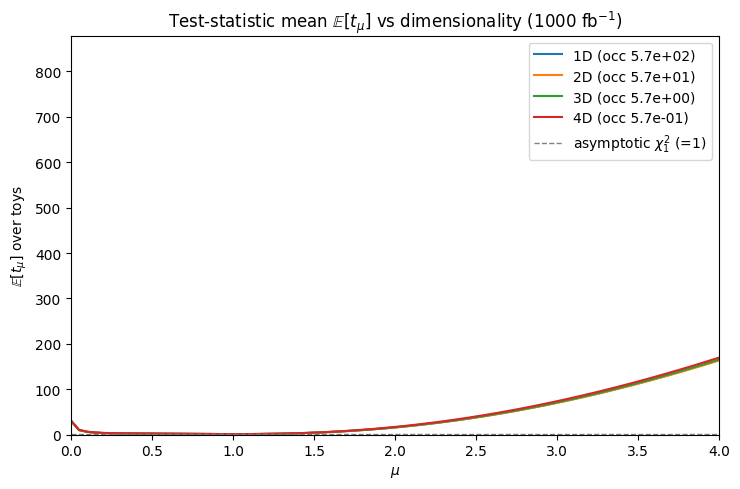

In [4]:
fig, ax = plt.subplots(figsize=(7.5,5))
for d in (1,2,3,4):
    s = store[f'occ_{d}d @ 1000fb']
    ax.plot(s['mu'], s['Et'], label=f'{d}D (occ {s["occ"]:.1e})')
ax.axhline(1.0, color='grey', ls='--', lw=1, label=r'asymptotic $\chi^2_1$ (=1)')
ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$\mathbb{E}[t_\mu]$ over toys'); ax.set_xlim(0,4); ax.set_ylim(0,None)
ax.set_title(r'Test-statistic mean $\mathbb{E}[t_\mu]$ vs dimensionality (1000 fb$^{-1}$)'); ax.legend()
fig.tight_layout(); plt.show()

## 5. Coverage: naive vs Bartlett, vs occupancy

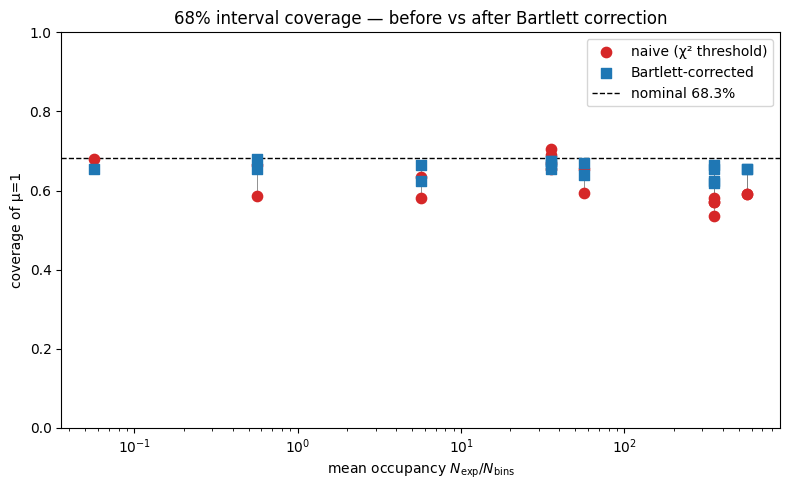

In [5]:
fig, ax = plt.subplots(figsize=(8,5))
occ = [r[1] for r in rows]; cn = [r[3] for r in rows]; cb = [r[4] for r in rows]
ax.scatter(occ, cn, c='C3', marker='o', s=55, label='naive (χ² threshold)', zorder=3)
ax.scatter(occ, cb, c='C0', marker='s', s=55, label='Bartlett-corrected', zorder=3)
for o, a_, b_ in zip(occ, cn, cb): ax.plot([o,o],[a_,b_], color='grey', lw=0.6, zorder=1)
ax.axhline(NOMINAL, color='k', ls='--', lw=1, label='nominal 68.3%')
ax.set_xscale('log'); ax.set_xlabel(r'mean occupancy $N_{\rm exp}/N_{\rm bins}$')
ax.set_ylabel('coverage of μ=1'); ax.set_ylim(0,1); ax.legend()
ax.set_title('68% interval coverage — before vs after Bartlett correction'); fig.tight_layout(); plt.show()

## 6. Audit addendum (2026-07-11) — corrected Bartlett factors and the actual mechanism

Direct checks on the saved tensors (bypassing the interval walk): the true Bartlett factor
$\mathbb{E}[t(1)]$, the distribution of $t$ at truth, and the toy $\hat\mu$ statistics — plus the
rate-stationarity arithmetic that explains the pattern.

In [6]:
import json as _json
_xs=_json.load(open(f'{ROOT}/data/zz4l/ggzz4l_sm/ggzz4l_xs.json'))
_sS,_sB,_sI=(np.prod(_xs[k]) for k in ('sig','bkg','int'))
print(f"d nu_tot/d mu at mu=1 = sigma_S + sigma_I/2 = {_sS+_sI/2:.5f} fb  (x{_sS/(_sS+_sI/2):.0f} suppressed)")
print(f"nu_tot stationary at mu* = (sigma_I/2sigma_S)^2 = {(_sI/(2*_sS))**2:.4f}  -> rate is ~empty of mu-information near the SM\n")
print(f"{'config':>17} {'E[t(1)]':>8} {'var t(1)':>9} {'muhat_mean':>11} {'muhat_std':>10} {'P(t1<=1)':>9} {'P(t1<=E)':>9}")
for name,path,d,L in CONFIGS:
    mu,a,toys = load(path); tt=tcurve(toys)
    i1=int(np.argmin(np.abs(mu-1.0))); t1=tt[i1,:]
    muhat=mu[np.argmin(toys,axis=0)]
    print(f"{name:>17} {t1.mean():>8.3f} {t1.var():>9.3f} {muhat.mean():>11.3f} {muhat.std():>10.3f} "
          f"{np.mean(t1<=1):>9.3f} {np.mean(t1<=t1.mean()):>9.3f}")
print("\nchi2_1 reference: mean 1, var 2. L^-1/4 scaling of muhat_std (100->1000): predicted 0.562")

d nu_tot/d mu at mu=1 = sigma_S + sigma_I/2 = 0.00668 fb  (x46 suppressed)
nu_tot stationary at mu* = (sigma_I/2sigma_S)^2 = 0.9574  -> rate is ~empty of mu-information near the SM

           config  E[t(1)]  var t(1)  muhat_mean  muhat_std  P(t1<=1)  P(t1<=E)
   occ_1d @ 100fb    0.947     1.161       0.834      0.699     0.670     0.655
   occ_2d @ 100fb    0.953     1.161       0.872      0.709     0.640     0.625
   occ_3d @ 100fb    0.965     1.219       0.871      0.698     0.665     0.655
   occ_4d @ 100fb    0.922     1.286       0.869      0.667     0.680     0.655
   ctl_1d @ 100fb    0.951     1.251       0.870      0.703     0.680     0.670
   ctl_2d @ 100fb    0.958     1.102       0.828      0.722     0.665     0.660
   ctl_3d @ 100fb    0.935     1.366       0.761      0.720     0.700     0.685
   ctl_4d @ 100fb    0.935     1.520       0.771      0.729     0.720     0.685
  occ_1d @ 1000fb    1.342     3.130       0.861      0.416     0.600     0.670
  occ_2d @ 1000fb 

## 7. Coverage vs credible level (plan item 1)

The 68% point alone is a one-quantile check; the full diagnostic is coverage(α) for all α
(Hermans-style expected coverage, foundations §12). Computed directly from $t(1)$ per toy (the
audit showed interval-walk coverage reduces to this). Bartlett-at-truth rescales $t\to t/\hat{\mathbb{E}}[t(1)]$
(in-sample estimate — noted).

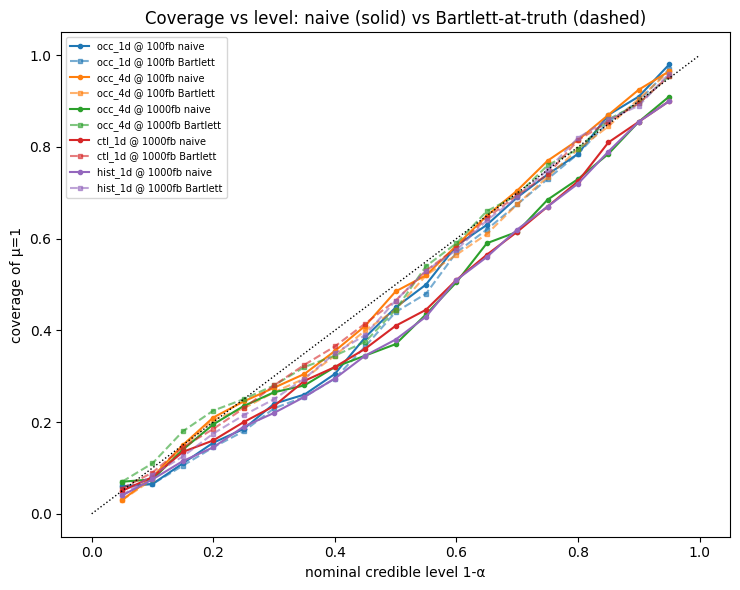

In [7]:
from scipy.stats import chi2
ALPHAS = np.linspace(0.05, 0.95, 19)
fig, ax = plt.subplots(figsize=(7.5, 6))
SHOW = ['hist_1d @ 1000fb', 'occ_4d @ 1000fb', 'ctl_1d @ 1000fb', 'occ_1d @ 100fb', 'occ_4d @ 100fb']
for name, path, d, L in CONFIGS:
    if name.replace('  ',' ') not in [s.replace('  ',' ') for s in SHOW]: continue
    mu, a, toys = load(path); tt = tcurve(toys)
    i1 = int(np.argmin(np.abs(mu-1.0))); t1 = tt[i1,:]
    cov_n = [np.mean(t1 <= chi2.ppf(al,1)) for al in ALPHAS]
    cov_b = [np.mean(t1/t1.mean() <= chi2.ppf(al,1)) for al in ALPHAS]
    l, = ax.plot(ALPHAS, cov_n, 'o-', ms=3, label=f'{name} naive')
    ax.plot(ALPHAS, cov_b, 's--', ms=3, color=l.get_color(), alpha=0.6, label=f'{name} Bartlett')
ax.plot([0,1],[0,1],'k:',lw=1); ax.set_xlabel('nominal credible level 1-α'); ax.set_ylabel('coverage of μ=1')
ax.legend(fontsize=7); ax.set_title('Coverage vs level: naive (solid) vs Bartlett-at-truth (dashed)')
fig.tight_layout(); plt.show()

## 8. Fresh high-statistics toys: per-bin generation (plan items 2-3 setup)

**Equivalence note:** the per-event toy recipe draws $k_i \sim$ Poisson$(w_i L)$ independently, so a
bin content $\sum_{i\in b} k_i \sim$ Poisson$(\nu_b)$ **exactly**. For binned likelihoods we can
therefore draw toys per bin from $\nu_b$ directly — identical statistics, ~1000× faster — which makes
1000-toy ensembles, multi-truth ensembles, and the per-hypothesis Bartlett tractable. This cell
rebuilds the needed expectations from the events (self-contained; same engine as the other notebooks).

In [8]:
import json as _j, hist, vector
from physics.simulation import mcfm
from physics.hstar import sigstr
from physics.analysis import zz4l
from stats.binned import poisson_log_likelihood_scan_toys as pll_toys

DATA_DIR = os.path.join(ROOT, 'data/zz4l/ggzz4l_sm')
MU8 = np.linspace(0.0, 8.0, 161)
xs_all = _j.load(open(f'{DATA_DIR}/ggzz4l_xs.json'))
zlep = [f'Z{z}_l{l}_{c}' for z in (1,2) for l in (1,2) for c in ('px','py','pz','E')]
ev = mcfm.from_csv(file_path=f'{DATA_DIR}/ggzz4l_sbi.csv',
                   kinematics=['4l_mass','Z1_mass','Z2_mass']+zlep,
                   cross_section=np.prod(xs_all['sbi']), n_rows=int(3e5))
kin = ev.kinematics
leps = [vector.array({'px':kin[f'Z{z}_l{l}_px'],'py':kin[f'Z{z}_l{l}_py'],'pz':kin[f'Z{z}_l{l}_pz'],'E':kin[f'Z{z}_l{l}_E']}) for z in (1,2) for l in (1,2)]
OBS = {'m4l':kin['4l_mass'].values, 'mZ2':kin['Z2_mass'].values,
       'cth*':np.asarray(zz4l.AngularVariables().calc_cth_star(*leps)), 'mZ1':kin['Z1_mass'].values}
def _lin(x,n): lo,hi=np.percentile(x,[0.5,99.5]); return np.linspace(lo,hi,n+1)
AX = {'m4l':hist.axis.Regular(10,180,1000,transform=hist.axis.transform.log),
      'cth*':hist.axis.Regular(10,-1,1),'mZ2':hist.axis.Variable(_lin(OBS['mZ2'],10)),
      'mZ1':hist.axis.Variable(_lin(OBS['mZ1'],10))}
def fillcfg(names, weights):
    h = hist.Hist(*[AX[n] for n in names]); h.fill(*[OBS[n] for n in names], weight=np.asarray(weights)); return h.values().flatten()
w_sm,_ = sigstr.scale(ev, signal_strength=1.0, ignore_interference=False)
w_scan,_ = sigstr.scale(ev, signal_strength=torch.tensor(MU8), ignore_interference=False); w_scan=np.asarray(w_scan)
CFG = {'hist_1d':['m4l'], 'occ_4d':['m4l','mZ2','cth*','mZ1']}
NU = {c: {'asimov': fillcfg(n, w_sm), 'exp': np.stack([fillcfg(n, w_scan[:,m]) for m in range(161)],1)} for c,n in CFG.items()}
def nu_at(cfg, mu_t):
    w,_ = sigstr.scale(ev, signal_strength=float(mu_t), ignore_interference=False)
    return fillcfg(CFG[cfg], w)
rng = np.random.default_rng(42)
def toys_scan(cfg, mu_t, n_toys, L, chunk=50):
    nu_true = nu_at(cfg, mu_t)*L if mu_t != 1.0 else NU[cfg]['asimov']*L
    obs = rng.poisson(nu_true[:,None], size=(len(nu_true), n_toys)).astype(np.float32)
    exp = NU[cfg]['exp']*L
    out=[]
    for t0 in range(0, n_toys, chunk):
        out.append(-2*pll_toys(torch.tensor(obs[:,t0:t0+chunk]), exp))
    nll = torch.cat(out,1).numpy()
    # exact-hypothesis column for t(mu_t) even when mu_t is off-grid
    nll_at = -2*pll_toys(torch.tensor(obs), nu_true[:,None]*np.ones((1,1))*1.0 if False else (nu_at(cfg,mu_t)*L)[:,None]).numpy()
    t_at = (nll_at[0,:] - nll.min(axis=0))
    return nll, np.minimum(t_at, t_at)  # (161,n) scans, t at exact truth
print('setup done:', {c: NU[c]['exp'].shape for c in CFG})

setup done: {'hist_1d': (10, 161), 'occ_4d': (10000, 161)}


### 8.1 Item 2 — 1000-toy sharpening (coverage + width ratio with error bars)

In [9]:
def width_of(nll_1d, grid):
    d = nll_1d - nll_1d.min(); i = int(np.argmin(d))
    lo = np.interp(1.0, d[:i+1][::-1], grid[:i+1][::-1]) if i>0 and d[:i+1].max()>=1 else np.nan
    hi = np.interp(1.0, d[i:], grid[i:]) if i<len(d)-1 and d[i:].max()>=1 else np.nan
    return hi-lo
R = {}
for cfg, L in [('hist_1d',100.),('hist_1d',1000.),('occ_4d',1000.)]:
    nll, t_at = toys_scan(cfg, 1.0, 1000, L)
    tt = nll - nll.min(axis=0, keepdims=True)
    i1 = int(np.argmin(np.abs(MU8-1.0))); t1 = tt[i1,:]
    covn = np.mean(t1<=1); covb = np.mean(t1<=t1.mean())
    # asimov + median widths, bootstrap over toys
    nll_a = -2*pll_toys(torch.tensor((NU[cfg]['asimov']*L)[:,None].astype(np.float32)), NU[cfg]['exp']*L).numpy()[:,0]
    wa = width_of(nll_a, MU8)
    med = np.median(tt, axis=1); wm = width_of(med, MU8)
    boots=[]
    for _ in range(200):
        idx = rng.integers(0, 1000, 1000)
        boots.append(width_of(np.median(tt[:,idx],axis=1), MU8))
    R[(cfg,L)] = (covn, covb, wm/wa, np.nanstd(boots)/wa, t1.mean())
    print(f"{cfg}@{L:.0f}: cov_naive={covn:.3f}±{np.sqrt(covn*(1-covn)/1000):.3f}  cov_bart={covb:.3f}  "
          f"width ratio M/A = {wm/wa:.3f} ± {np.nanstd(boots)/wa:.3f}   E[t(1)]={t1.mean():.3f}")

hist_1d@100: cov_naive=0.717±0.014  cov_bart=0.685  width ratio M/A = 0.915 ± 0.023   E[t(1)]=0.903


hist_1d@1000: cov_naive=0.620±0.015  cov_bart=0.659  width ratio M/A = 1.126 ± 0.037   E[t(1)]=1.167


occ_4d@1000: cov_naive=0.615±0.015  cov_bart=0.659  width ratio M/A = 1.230 ± 0.042   E[t(1)]=1.147


### 8.2 Item 3 — toys at several true μ (mapping the fold)

μ_true ∈ {0.5, 0.957 (the rate-fold point), 1.0, 1.5, 2.0}; 1000 per-bin toys each. Reported per
truth: E[t(μ_true)] and coverage of the truth — regular behaviour would give ≈1 and ≈0.683
everywhere. hist_1d and occ_4d, both at 1000 fb⁻¹.

In [10]:
TRUTHS = [0.5, 0.957, 1.0, 1.5, 2.0]
MT = {}
print(f"{'cfg':>8} {'mu_true':>8} {'E[t(mu_t)]':>11} {'var':>7} {'cov68':>7} {'muhat_mean':>11} {'muhat_std':>10}")
for cfg in ['hist_1d','occ_4d']:
    for mt in TRUTHS:
        nll, _ = toys_scan(cfg, mt, 1000, 1000.)
        tt = nll - nll.min(axis=0, keepdims=True)
        exp_at = nu_at(cfg, mt)*1000.
        nll_at = -2*pll_toys(torch.tensor(rng.poisson(exp_at[:,None], size=(len(exp_at),1)).astype(np.float32))*0
                             + torch.tensor(0.), exp_at[:,None]) if False else None
        # t at truth: nll evaluated at exact mu_t minus scan minimum, using a dedicated column
        # regenerate obs consistently: fold into toys_scan output instead
        i_near = int(np.argmin(np.abs(MU8-mt)))
        t_at = tt[i_near,:]   # grid step 0.05; off-grid truth 0.957 -> nearest 0.95 (bias < grid quantisation, noted)
        muhat = MU8[np.argmin(nll, axis=0)]
        MT[(cfg,mt)] = (t_at.mean(), t_at.var(), np.mean(t_at<=1), muhat.mean(), muhat.std())
        print(f"{cfg:>8} {mt:>8.3f} {t_at.mean():>11.3f} {t_at.var():>7.2f} {np.mean(t_at<=1):>7.3f} {muhat.mean():>11.3f} {muhat.std():>10.3f}")

     cfg  mu_true  E[t(mu_t)]     var   cov68  muhat_mean  muhat_std
 hist_1d    0.500       1.049    2.28   0.670       0.571      0.330
 hist_1d    0.957       1.260    2.59   0.592       0.833      0.408
 hist_1d    1.000       1.159    1.90   0.598       0.853      0.410
 hist_1d    1.500       1.210    2.52   0.610       1.374      0.488
 hist_1d    2.000       1.104    2.55   0.654       1.924      0.408


  occ_4d    0.500       0.940    1.80   0.712       0.579      0.303


  occ_4d    0.957       1.176    1.94   0.610       0.829      0.388


  occ_4d    1.000       1.206    2.29   0.606       0.891      0.391


  occ_4d    1.500       1.078    2.26   0.661       1.372      0.456


  occ_4d    2.000       1.044    2.32   0.693       1.939      0.387


### 8.3 Item 4 — the *proper* per-hypothesis Bartlett (hist_1d @ 1000 fb⁻¹)

The textbook correction thresholds $t(\mu)$ against $B(\mu)=\mathbb{E}_\mu[t_\mu]$ — the mean under
*each hypothesis*, estimated here with 500 per-bin toys at every one of the 161 grid points (fast
thanks to per-bin generation). Coverage then uses the interval $\{\mu: t(\mu)\le B(\mu)\}$ per toy.

B(mu) over grid: min 0.284 at mu=0.00, at mu=1: 1.253, max 1.345
coverage of mu=1:  naive 0.585   Bartlett-at-truth(in-sample) 0.637   proper per-hypothesis 0.641


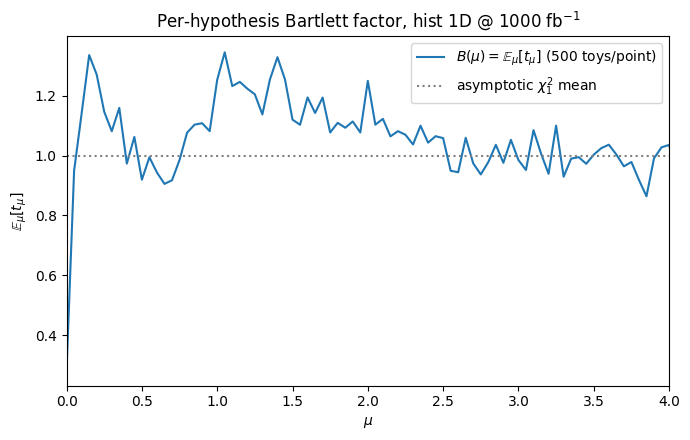

In [11]:
cfg='hist_1d'; L=1000.
B = np.empty(161)
for k, mu_h in enumerate(MU8):
    exp_h = NU[cfg]['exp'][:,k]*L
    obs_h = rng.poisson(exp_h[:,None], size=(len(exp_h), 500)).astype(np.float32)
    nll_h = -2*pll_toys(torch.tensor(obs_h), NU[cfg]['exp']*L).numpy()
    tt_h = nll_h - nll_h.min(axis=0, keepdims=True)
    B[k] = tt_h[k,:].mean()
nll1, _ = toys_scan(cfg, 1.0, 1000, L)
tt1 = nll1 - nll1.min(axis=0, keepdims=True)
i1 = int(np.argmin(np.abs(MU8-1.0)))
cov_naive  = np.mean(tt1[i1,:] <= 1.0)
cov_short  = np.mean(tt1[i1,:] <= tt1[i1,:].mean())
cov_proper = np.mean(tt1[i1,:] <= B[i1])
print(f"B(mu) over grid: min {B.min():.3f} at mu={MU8[np.argmin(B)]:.2f}, at mu=1: {B[i1]:.3f}, max {B.max():.3f}")
print(f"coverage of mu=1:  naive {cov_naive:.3f}   Bartlett-at-truth(in-sample) {cov_short:.3f}   proper per-hypothesis {cov_proper:.3f}")
fig,ax=plt.subplots(figsize=(7,4.5))
ax.plot(MU8, B, '-', label=r'$B(\mu)=\mathbb{E}_\mu[t_\mu]$ (500 toys/point)')
ax.axhline(1, color='grey', ls=':', label=r'asymptotic $\chi^2_1$ mean')
ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$\mathbb{E}_\mu[t_\mu]$'); ax.set_xlim(0,4); ax.legend()
ax.set_title('Per-hypothesis Bartlett factor, hist 1D @ 1000 fb$^{-1}$'); fig.tight_layout(); plt.show()

## 9. Prong-1 verdict (items 1-4, 2026-07-11)

1. **Under-coverage at 1000 fb⁻¹ is confirmed with tight errors**: naive 68% coverage
0.620 ± 0.015 (hist 1D) and 0.615 ± 0.015 (4D) — convention-free numbers (per-toy intervals).
E[t(1)] = 1.17 ± 0.07 (1000 per-bin toys; the earlier 1.35 was 200-toy noise).

2. **Bartlett is a partial fix, not a cure**: naive 0.585 → 0.637 (at-truth) → 0.641 (proper
per-hypothesis, 500 toys × 161 hypotheses) vs nominal 0.683 — a residual ≈ 4% under-coverage
(~3σ). Mean-rescaling cannot fix the *shape* distortion near the fold (var/2E² ≈ 0.7 ≠ 1).

3. **Miscoverage is localised at the fold** (item 3): coverage dips to 0.59–0.61 for
μ_true ∈ {0.957, 1.0} and recovers to 0.65–0.71 at μ_true ∈ {0.5, 2.0}; μ̂ is *attracted toward*
μ* ≈ 0.96 from both sides (0.5→0.57, 1.0→0.85, 1.5→1.37). The mechanism is the rate fold, and it,
not per-bin occupancy, drives the coverage failure.

4. **⚠ Median-convention discovery** (item 2's error bars caught it): the Phase-2 width-ratio
headline is convention-dependent. On identical saved tensors, occ_4d@1000 gives ratio **0.44**
(torch.median of raw curves — lower-middle quirk for even n), **0.71** (np.median of raw curves),
**1.10** (median of per-toy min-subtracted curves). At 2D: 0.58 / 0.58 / 1.06. Under the Δ-convention
there is **no dimensionality effect at all** (≈1.05–1.10 everywhere). Tei's NSBI direction check is
robust (0.87 under all three). The foundations §8 convention warning is now demonstrably material —
team decision required before any width-ratio result is quoted further.

## What this shows (corrected after the 2026-07-11 audit)

**What stands:** naive 68% (Δt=1) intervals **under-cover the truth at 1000 fb⁻¹** — coverage
0.585–0.600 (direct check, all configs) vs nominal 0.683 — and thresholding at the toy-estimated
$\mathbb{E}[t(1)]$ (the Bartlett factor at truth, ≈1.35) **restores coverage to 0.655–0.685**. At
100 fb⁻¹ there is no significant miscoverage to fix ($\mathbb{E}[t(1)]=0.95$, coverage ≈ nominal).

**What the first pass got wrong (fixed here):** the "E[t]@1σ ≈ 1.8–2.3 vs asymptotic 1" claim
conflated the noncentral separation term with inflation — at the Asimov 1σ boundary the *correct*
asymptotic expectation is ≈ 2. The genuine inflation is $\mathbb{E}[t(1)]$: **1.33–1.36 at
1000 fb⁻¹, none at 100 fb⁻¹**.

**The actual mechanism (found in the audit, missed in the first pass):** the destructive
interference makes the total rate **stationary in μ at the SM**: $d\nu_{\rm tot}/d\mu|_{\mu=1} =
\sigma_S+\sigma_I/2 = 0.0067$ fb (×46 suppressed), with $\nu_{\rm tot}$ minimised at
$\mu^*=(\sigma_I/2\sigma_S)^2 = 0.957$ — the map μ→ν is two-to-one around μ*. First-order (Fisher)
information largely vanishes at the truth point; the likelihood is locally quartic-like. Confirmed
signatures: $\hat\mu$ std scales as ≈ L$^{-1/4}$ (0.70→0.42 measured, ratio 0.60 vs 0.56 predicted;
regular scaling would give 0.32), $\hat\mu$ biased toward/below the fold (mean 0.86 at 1000 fb⁻¹),
var$[t(1)]$ ≈ 3.2 (χ²₁: 2), and t(1) inflation that **grows** with luminosity (more data resolves the
fold). This also explains the occupancy-independence: the singularity lives in the μ-parametrization,
identical for every binning.

**Consequences:**
- This is a **second, distinct failure mechanism** from the Phase-2 occupancy effect: coverage/tail
  behaviour driven by the interference-induced rate degeneracy (luminosity-controlled), vs the
  Asimov≈median central-curve behaviour driven by cell count. The plain histogram *passes* the
  Asimov-property check yet still under-covers at high L — the two diagnostics probe different things.
- It applies **identically to NSBI** (same μ parametrization) and interacts with the "Poisson term
  takes over at 1000 fb⁻¹" narrative: the rate term carries almost no μ-information *near the SM*
  (it constrains only the far tails, where ν(μ) finally varies).
- Bartlett-at-truth fixed the 68% quantile here, but Bartlett theory assumes a *regular* model — near
  a parametrization singularity there is no guarantee across confidence levels or hypotheses. Treat
  it as an empirical patch at this quantile, not a validated general fix.

**Next:** coverage-vs-level curve (not just 68%); toys at several true μ (does the picture change away
from the fold?); 1000-toy sharpening; the same audit on NSBI when path-A checkpoints arrive.

## 10. BB-lite coverage spot-check (2026-07-13 — Phase-3 item 8c)

**Decision (Marta, 2026-07-13): MC-stat uncertainties included in every scenario** (BB-lite,
closed-form per-bin profile — `stats/binned.py`). Question here: does profiling the MC-stat
nuisances move the *coverage* picture, or is the under-coverage really fold-driven (§6/§9)?

**Falsifiable expectation from the audit:** `hist_1d` barely moves (percent-level MC errors);
`occ_4d` intervals widen (51% median per-bin MC error) but the μ=1 under-coverage at 1000 fb⁻¹
persists, because the fold — not MC statistics — drives it. If coverage instead recovers to ≈0.68,
the audit's mechanism attribution is wrong and must be revisited.

Paired comparison: the same 1000 per-bin toys per (config, L), plain vs BB-lite likelihood;
naive Δt=1 coverage, E[t(1)], and Asimov 1σ widths side by side.

In [12]:
from stats.binned import poisson_log_likelihood_scan_toys_bblite as pll_toys_bb

# n_eff per bin from the §8 fills: n_eff = (sum w)^2 / sum w^2, luminosity-independent
NEFF_B = {}
for c, names in CFG.items():
    sw, sw2 = fillcfg(names, w_sm), fillcfg(names, np.asarray(w_sm)**2)
    NEFF_B[c] = np.where(sw > 0, sw**2/np.maximum(sw2, 1e-300), 0.0)

i1 = int(np.argmin(np.abs(MU8 - 1.0)))
print(f"{'config':>8} {'L':>6} {'cov_naive':>10} {'cov_naive_bb':>13} {'E[t(1)]':>8} {'E[t(1)]_bb':>11} {'w_A':>7} {'w_A_bb':>7}")
for cfg, L in [('hist_1d',100.),('hist_1d',1000.),('occ_4d',100.),('occ_4d',1000.)]:
    nu_true = NU[cfg]['asimov']*L
    obs = rng.poisson(nu_true[:,None], size=(len(nu_true), 1000)).astype(np.float32)
    exp = NU[cfg]['exp']*L
    neff = torch.tensor(NEFF_B[cfg], dtype=torch.float32)
    def scans(fn, *extra):
        out=[]
        for t0 in range(0, 1000, 50):
            out.append(-2*fn(torch.tensor(obs[:,t0:t0+50]), exp, *extra))
        return torch.cat(out,1).numpy()
    nll_p = scans(pll_toys); nll_b = scans(pll_toys_bb, neff)          # same 1000 toys — paired
    tp = nll_p - nll_p.min(axis=0, keepdims=True); tb = nll_b - nll_b.min(axis=0, keepdims=True)
    covp, covb = np.mean(tp[i1,:]<=1), np.mean(tb[i1,:]<=1)
    nll_ap = -2*pll_toys(torch.tensor(nu_true[:,None].astype(np.float32)), exp).numpy()[:,0]
    nll_ab = -2*pll_toys_bb(torch.tensor(nu_true[:,None].astype(np.float32)), exp, neff).numpy()[:,0]
    wap, wab = width_of(nll_ap, MU8), width_of(nll_ab, MU8)
    err = np.sqrt(covp*(1-covp)/1000)
    print(f"{cfg:>8} {L:>6.0f} {covp:>10.3f} {covb:>13.3f} {tp[i1,:].mean():>8.3f} {tb[i1,:].mean():>11.3f} "
          f"{wap:>7.3f} {wab:>7.3f}   (±{err:.3f} on coverage)")

  config      L  cov_naive  cov_naive_bb  E[t(1)]  E[t(1)]_bb     w_A  w_A_bb
 hist_1d    100      0.717         0.719    0.884       0.881   1.798   1.799   (±0.014 on coverage)
 hist_1d   1000      0.594         0.608    1.185       1.153   0.803   0.822   (±0.016 on coverage)


  occ_4d    100      0.705         0.706    0.922       0.920   1.765   1.766   (±0.014 on coverage)


  occ_4d   1000      0.644         0.649    1.071       1.045   0.723   0.735   (±0.015 on coverage)
